# 04. Порівняння експериментів з FCOS

У цьому ноутбуці порівнюємо три варіанти FCOS. Спочатку ми навчали базову модель із початковими налаштуваннями. Потім провели два окремі експерименти: у першому зменшили learning rate до `5e-5`, а в другому змінили параметр `gamma` у Focal Loss на `1.5`.

## 1. Підготовка даних для аналізу

Результати попередніх запусків беремо з Kaggle Inputs. Для baseline метрики перших двох folds збережені в датасеті `folds_0_1`, а результат третього fold — у вихідних файлах notebook `01-baseline`. Результати експериментів зі зміненими learning rate та gamma зчитуємо з архівів, збережених у `02-experiment1` і `03-experiment2`.

In [21]:
from pathlib import Path
import json
import zipfile
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

INPUT = Path('/kaggle/input')
OUT = Path('/kaggle/working/fcos_analysis')
OUT.mkdir(parents=True, exist_ok=True)
METRICS = ['mAP', 'AP50', 'AP75', 'AP_small', 'AP_medium', 'AP_large']


## 2. Зчитування метрик

Для кожного експерименту зчитуємо результати всіх трьох folds. Основна метрика для порівняння — `mAP`: вона дає загальну оцінку якості детекції за різних порогів IoU. Також дивимося на `AP50` та `AP75`. У першому випадку використовується поріг IoU 0.50, а в другому 0.75. Тому `AP75` допомагає оцінити, наскільки точно модель розташовує рамки навколо об'єктів.

IoU показує, наскільки передбачена рамка перекривається з правильною рамкою об'єкта. Чим краще вони збігаються, тим більшим є значення IoU. Окремо розглядаємо `AP_small`, `AP_medium` та `AP_large`, щоб побачити різницю між детекцією малих, середніх і великих об'єктів. Для відео з дронів це важливо, адже багато об'єктів на кадрах дуже дрібні.


In [22]:

def locate_baseline(fold):
    candidates = [
        p for p in INPUT.rglob('metrics_quick.json')
        if p.parent.name == f'fold_{fold}'
        and ('folds-0-1' in str(p) or 'folds_0_1' in str(p))
    ] if fold in (0, 1) else [
        p for p in INPUT.rglob('metrics_quick.json')
        if p.parent.name == 'fold_2' and '01-baseline' in str(p)
    ]
    if not candidates:
        raise FileNotFoundError(f'Baseline Fold {fold} metrics not found. Check Kaggle Add Input.')
    return sorted(candidates, key=str)[0]

def find_zip(filename):
    matches = list(INPUT.rglob(filename))
    if not matches:
        raise FileNotFoundError(f'{filename} not found. Add the tuning notebook Output as Input.')
    return sorted(matches, key=lambda p: ('/notebooks/' not in str(p), str(p)))[0]

lr_zip = find_zip('fcos_lr_5e5_metrics.zip')
gamma_zip = find_zip('fcos_gamma_1p5_metrics.zip')
print('LR archive:', lr_zip)
print('Gamma archive:', gamma_zip)

rows = []
for fold in range(3):
    path = locate_baseline(fold)
    print(f'Baseline fold {fold}:', path)
    metrics = json.loads(path.read_text(encoding='utf8'))
    rows.append({'experiment': 'Baseline', 'fold': fold, **{k: metrics[k] for k in METRICS}})

for name, archive in [('LR 5e-5', lr_zip), ('Gamma 1.5', gamma_zip)]:
    with zipfile.ZipFile(archive) as z:
        for fold in range(3):
            metrics = json.loads(z.read(f'fold_{fold}/metrics_quick.json'))
            rows.append({'experiment': name, 'fold': fold, **{k: metrics[k] for k in METRICS}})

results = pd.DataFrame(rows)
assert len(results) == 9
assert results[METRICS].notna().all().all()
display(results.round(4))


LR archive: /kaggle/input/notebooks/alinabodnar05/02-experiment1/fcos_lr_5e5_metrics.zip
Gamma archive: /kaggle/input/notebooks/alinabodnar05/03-experiment2/fcos_gamma_1p5_metrics.zip
Baseline fold 0: /kaggle/input/datasets/alinabodnar05/folds-0-1/fold_0/metrics_quick.json
Baseline fold 1: /kaggle/input/datasets/alinabodnar05/folds-0-1/fold_1/metrics_quick.json
Baseline fold 2: /kaggle/input/notebooks/alinabodnar05/01-baseline/fcos_baseline/fold_2/metrics_quick.json


,experiment,fold,mAP,AP50,AP75,AP_small,AP_medium,AP_large
0,Baseline,0,0.1714,0.3473,0.1514,0.0693,0.1434,0.2523
1,Baseline,1,0.1240,0.2367,0.1153,0.0289,0.1293,0.2778
2,Baseline,2,0.1459,0.2913,0.1301,0.0494,0.1480,0.2902
3,LR 5e-5,0,0.1777,0.3534,0.1600,0.0686,0.1397,0.2713
4,LR 5e-5,1,0.1382,0.2693,0.1240,0.0271,0.1408,0.3039
5,LR 5e-5,2,0.1523,0.3036,0.1378,0.0517,0.1524,0.3016
6,Gamma 1.5,0,0.1749,0.3555,0.1538,0.0717,0.1436,0.2436
7,Gamma 1.5,1,0.1332,0.2626,0.1204,0.0276,0.1399,0.2768
8,Gamma 1.5,2,0.1474,0.2958,0.1325,0.0525,0.1463,0.3059


## 3. Порівняння середніх результатів

Один fold не завжди добре показує загальну якість моделі, бо різні відеокліпи можуть відрізнятися за складністю. Тому спочатку обчислюємо середнє значення кожної метрики за трьома folds. Саме за середнім `mAP` будемо обирати найкращий варіант FCOS.

Додатково рахуємо стандартне відхилення (`std`), щоб побачити, наскільки сильно результати відрізняються між folds. Якщо воно менше, значення на трьох folds ближчі одне до одного. Але це ще не гарантує, що модель однаково добре працюватиме на всіх нових відео.

Також обчислюємо різницю між кожним tuning-експериментом і baseline. Наприклад, зміна `mAP` на `+0.009` означає, що показник збільшився на 0.009 абсолютного значення.

In [23]:
order = ['Baseline', 'LR 5e-5', 'Gamma 1.5']
mean = results.groupby('experiment')[METRICS].mean().loc[order]
std = results.groupby('experiment')[METRICS].std().loc[order]
delta = mean.subtract(mean.loc['Baseline'])

print('Mean COCO metrics:')
display(mean.round(4))
print('Std across folds:')
display(std.round(4))
print('Absolute change vs baseline:')
display(delta.round(4))


Mean COCO metrics:


,mAP,AP50,AP75,AP_small,AP_medium,AP_large
experiment,,,,,,
Baseline,0.1471,0.2918,0.1323,0.0492,0.1402,0.2734
LR 5e-5,0.1561,0.3087,0.1406,0.0492,0.1443,0.2922
Gamma 1.5,0.1518,0.3046,0.1356,0.0506,0.1433,0.2754


Std across folds:


,mAP,AP50,AP75,AP_small,AP_medium,AP_large
experiment,,,,,,
Baseline,0.0237,0.0553,0.0182,0.0202,0.0097,0.0193
LR 5e-5,0.0200,0.0423,0.0182,0.0209,0.0070,0.0182
Gamma 1.5,0.0212,0.0471,0.0169,0.0221,0.0032,0.0311


Absolute change vs baseline:


,mAP,AP50,AP75,AP_small,AP_medium,AP_large
experiment,,,,,,
Baseline,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
LR 5e-5,0.0090,0.0170,0.0084,-0.0001,0.0041,0.0188
Gamma 1.5,0.0047,0.0129,0.0033,0.0014,0.0031,0.0020


## 4. Візуалізація результатів

Спочатку побудуємо графік `mAP` для кожного fold. На ньому можна порівняти baseline з обома tuning-експериментами й побачити, чи покращення повторюється на всіх трьох folds. Це корисно, бо вище середнє значення іноді може бути наслідком дуже хорошого результату лише на одному наборі відео.

Другий графік показує якість детекції залежно від розміру об'єктів. Ми порівнюємо середні `AP_small`, `AP_medium` та `AP_large` для кожного варіанта FCOS. Так можна зрозуміти, чи налаштування допомогли саме з малими об'єктами, які на наших відео виявляти найважче.

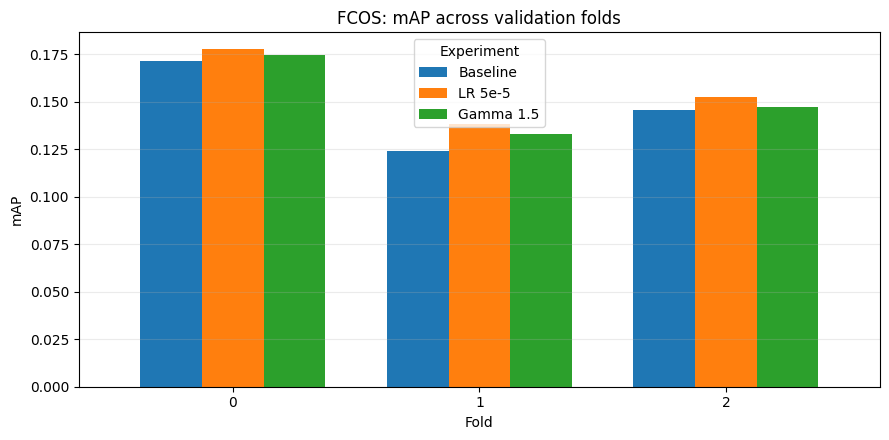

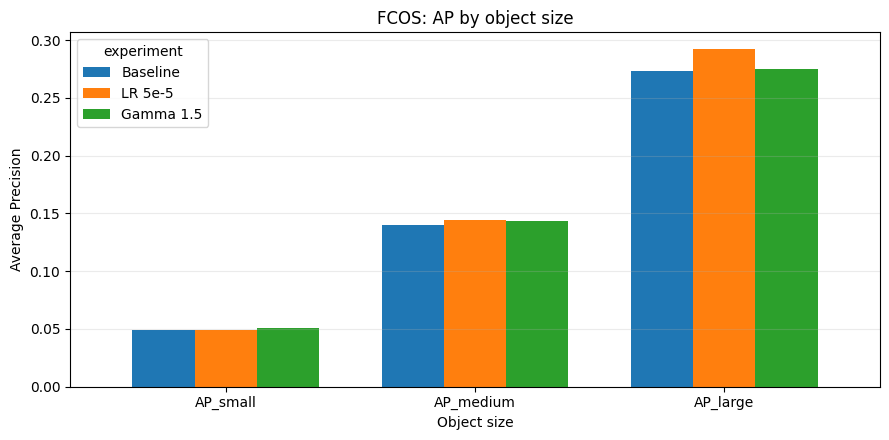

In [24]:

plot_data = results.pivot(index='fold', columns='experiment', values='mAP')[order]
ax = plot_data.plot.bar(figsize=(9, 4.5), width=0.75)
ax.set(title='FCOS: mAP across validation folds', xlabel='Fold', ylabel='mAP')
ax.legend(title='Experiment')
ax.grid(axis='y', alpha=0.25)
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig(OUT / 'map_by_fold.png', dpi=160)
plt.show()

ax = mean[['AP_small', 'AP_medium', 'AP_large']].T.plot.bar(figsize=(9, 4.5), width=0.75)
ax.set(title='FCOS: AP by object size', xlabel='Object size', ylabel='Average Precision')
ax.grid(axis='y', alpha=0.25)
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig(OUT / 'ap_by_size.png', dpi=160)
plt.show()


## 5. Що показали експерименти

За середнім `mAP` найкращою виявилася модель зі зменшеним learning rate. У baseline ми отримали приблизно `0.1471`, а після зміни learning rate на `5e-5` — `0.1561`. Тобто якість покращилася приблизно на `0.0090`. Зміна gamma у Focal Loss також дала покращення, але менше: середній `mAP` становив близько `0.1518`.

Важливо, що в обох експериментах `mAP` зріс на кожному з трьох folds. Отже, покращення середнього результату не пов'язане тільки з одним вдалим fold. Проте різниця між експериментами не дуже велика, тому не можемо робити висновок, що один підхід завжди буде кращим на будь-яких даних.

Найскладнішою для всіх варіантів залишилася детекція малих об'єктів. Менший learning rate покращив загальний `mAP`, проте майже не змінив `AP_small`. Після зміни gamma цей показник трохи зріс, але загальна якість усе одно виявилася нижчою, ніж у моделі з `LR = 5e-5`.

Для подальшого порівняння з іншими архітектурами обираємо **FCOS із `LR = 5e-5`**, адже вона показала найкращий середній `mAP` на наших трьох folds. 

In [25]:
best = mean['mAP'].idxmax()
print(f'Best mean mAP: {best}, {mean.loc[best, "mAP"]:.4f}')
for name in order[1:]:
    paired = plot_data[name] - plot_data['Baseline']
    print(f'{name}: Δmean mAP = {delta.loc[name, "mAP"]:+.4f}; '
          f'improved folds = {(paired > 0).sum()}/3; '
          f'ΔAP_small = {delta.loc[name, "AP_small"]:+.4f}')



Best mean mAP: LR 5e-5, 0.1561
LR 5e-5: Δmean mAP = +0.0090; improved folds = 3/3; ΔAP_small = -0.0001
Gamma 1.5: Δmean mAP = +0.0047; improved folds = 3/3; ΔAP_small = +0.0014


## 6. Збереження результатів

In [26]:
import shutil
results.to_csv(OUT / 'fold_metrics.csv', index=False)
mean.to_csv(OUT / 'mean_metrics.csv')
std.to_csv(OUT / 'std_metrics.csv')
delta.to_csv(OUT / 'delta_vs_baseline.csv')
zip_path = shutil.make_archive('/kaggle/working/fcos_analysis', 'zip', OUT)
print('Saved:', zip_path)


Saved: /kaggle/working/fcos_analysis.zip
